# 03 — Cechy, modele, walidacja

**Cel notebooka:**
1. Zamienić surowe dane na **cechy** — liczby opisujące sytuację kierowcy *przed* startem wyścigu.
2. Zdefiniować **baseline** i uczciwą **walidację**.
3. Sprawdzić, czy model ML jest lepszy od baseline'u.

**Decyzja projektowa (droga B z naszej rozmowy):** zamiast trzech osobnych klasyfikatorów (wygra? / top 3? / top 10?) budujemy **jeden model, który przewiduje pozycję na mecie**. Sortujemy kierowców po przewidywanej pozycji i z tej jednej listy odczytujemy zwycięzcę, podium i top 10. Zalety:
- wyniki są spójne (nie da się mieć większej szansy na wygraną niż na podium),
- każdy wiersz uczy model (przy klasyfikatorze „wygra?” tylko 1 na 22 to przykład pozytywny — *class imbalance*).

**Najszybsze okrążenie** to inny problem (strategia, opony) — dostaje osobny klasyfikator.

## 3.0 Wczytanie danych

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

races = pd.read_csv("data/races_2026.csv")
results = pd.read_csv("data/results_2026.csv")
quali = pd.read_csv("data/quali_2026.csv")
sprint = pd.read_csv("data/sprint_2026.csv")
fastest_laps = pd.read_csv("data/fastest_laps_2026.csv")
teammate_hist = pd.read_csv("data/teammate_gaps_hist.csv")

N_DRIVERS = 22
FINISHED_ROUNDS = races.loc[races["finished"], "round"].tolist()

## 3.1 Tabela bazowa: jeden wiersz = kierowca w weekendzie

**Co robimy:** zaczynamy od **kwalifikacji**, nie od wyników wyścigu.

**Dlaczego:** dla Singapuru wyniku wyścigu jeszcze nie ma, ale kwalifikacje są. Jeśli tabela cech powstaje z kwalifikacji, to Singapur dostaje swoje wiersze tak samo jak każdy wcześniejszy weekend — i cechy liczymy dla wszystkich jednym kodem. Wynik wyścigu doklejamy jako **zmienną docelową** (dla Singapuru zostanie pusta).

In [2]:
data = quali[["round", "meeting_key", "driver_number", "name_acronym", "team_name", "position", "gap_to_pole_pct"]]
data = data.rename(columns={"position": "grid"})

res = results[["round", "driver_number", "position", "points", "dnf", "dns"]].rename(columns={"position": "finish"})
data = data.merge(res, on=["round", "driver_number"], how="left")

done = data["round"].isin(FINISHED_ROUNDS)
data.loc[done, "finish"] = data.loc[done, "finish"].fillna(N_DRIVERS)
data["retired"] = (data["dnf"] == True) | (data["dns"] == True)

fl = fastest_laps[["round", "driver_number"]].assign(fastest_lap=1)
data = data.merge(fl, on=["round", "driver_number"], how="left")
data.loc[done, "fastest_lap"] = data.loc[done, "fastest_lap"].fillna(0)

data = data.sort_values(["round", "grid"]).reset_index(drop=True)
print(data.shape, "| weekendy:", data["round"].nunique())
data.tail()

(369, 13) | weekendy: 17


,round,meeting_key,driver_number,name_acronym,team_name,grid,gap_to_pole_pct,finish,points,dnf,dns,retired,fastest_lap
364,17,1296,23,ALB,Williams,18.0,3.191315,NaN,NaN,NaN,NaN,False,NaN
365,17,1296,18,STR,Aston Martin,19.0,3.910346,NaN,NaN,NaN,NaN,False,NaN
366,17,1296,11,PER,Cadillac,20.0,4.104057,NaN,NaN,NaN,NaN,False,NaN
367,17,1296,77,BOT,Cadillac,21.0,5.046348,NaN,NaN,NaN,NaN,False,NaN
368,17,1296,6,HAD,Red Bull Racing,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN


**Co tu się dzieje:**
- `done` — maska „ten weekend ma już wynik wyścigu”. Tylko tam zamieniamy brak pozycji na 22 (DNF bez klasyfikacji = ostatni). Dla Singapuru `finish` zostaje `NaN` — nie wiemy, jak będzie, i nie udajemy, że wiemy.
- `(data["dnf"] == True)` zamiast samego `data["dnf"]` — po `merge` Singapur ma tam `NaN`, a `== True` bezpiecznie zamienia `NaN` na `False`.
- `fastest_lap` = 1 dla zdobywcy najszybszego okrążenia, 0 dla reszty.

## 3.2 Cechy

Każda cecha musi spełniać jedną zasadę: **dla wyścigu w rundzie *r* używa tylko informacji dostępnych przed startem tego wyścigu**. Złamanie tej zasady to *data leakage* (wyciek z przyszłości): model w walidacji wygląda świetnie, a w prawdziwej predykcji zawodzi, bo „podglądał” odpowiedzi.

| Cecha | Skąd | Znana przed startem? |
|---|---|---|
| `grid` | kwalifikacje tego weekendu | ✅ sobota |
| `gap_to_pole_pct` | kwalifikacje tego weekendu | ✅ sobota |
| `sprint_pos` | sprint tego weekendu (albo `grid`, gdy sprintu nie było) | ✅ sobota |
| `driver_form` | średnia pozycja z **3 poprzednich** wyścigów | ✅ — dzięki `shift(1)` |
| `team_points_avg` | średnie punkty zespołu na wyścig **do poprzedniej rundy** | ✅ — dzięki `shift(1)` |
| `team_dnf_rate` | udział wycofań zespołu **do poprzedniej rundy** | ✅ — dzięki `shift(1)` |
| `driver_skill` | różnica do partnera w kwalifikacjach 2023–2025 | ✅ historia |

### 3.2a Cechy z tego weekendu: kwalifikacje i sprint

In [3]:
data["grid"] = data["grid"].fillna(N_DRIVERS)
data["gap_to_pole_pct"] = data["gap_to_pole_pct"].fillna(data.groupby("round")["gap_to_pole_pct"].transform("max"))

sp = sprint[["round", "driver_number", "position"]].rename(columns={"position": "sprint_pos"})
data = data.merge(sp, on=["round", "driver_number"], how="left")
data["sprint_pos"] = data["sprint_pos"].fillna(data["grid"])

**Co tu się dzieje:**
- Kierowca bez czasu w kwalifikacjach: `grid` = 22, a `gap_to_pole_pct` = najgorsza strata z jego weekendu.
- `sprint_pos` — w weekendach bez sprintu (i dla kierowcy, który sprintu nie ukończył) wpisujemy pozycję z kwalifikacji. To neutralne uzupełnienie: „sprint nic nowego nie powiedział”.

### 3.2b Forma kierowcy i siła zespołu — tylko z przeszłości

**Kluczowy trik: `shift(1)`.** Dla każdego kierowcy (albo zespołu) sortujemy rundy rosnąco i przesuwamy kolumnę o jeden wiersz w dół. Wtedy w wierszu rundy *r* stoi wartość z rundy *r−1* — a średnia krocząca liczy się tylko z przeszłości.

```
runda:   1    2    3    4
finish:  3    1    5    2
shift:   NaN  3    1    5      ← dla rundy 4 widzimy tylko rundy 1–3
```

In [4]:
data["driver_form"] = data.groupby("name_acronym")["finish"].transform(
    lambda s: s.shift(1).rolling(3, min_periods=1).mean()
)

team_round = (
    data.groupby(["team_name", "round"])
    .agg(team_points=("points", "sum"), team_retired=("retired", "mean"))
    .reset_index()
    .sort_values("round")
)
g = team_round.groupby("team_name")
team_round["team_points_avg"] = g["team_points"].transform(lambda s: s.shift(1).expanding().mean())
team_round["team_dnf_rate"] = g["team_retired"].transform(lambda s: s.shift(1).expanding().mean())

data = data.merge(team_round[["team_name", "round", "team_points_avg", "team_dnf_rate"]],
                  on=["team_name", "round"], how="left")
first_race = data["driver_form"].isna() & (data["round"] > 1)
data.loc[first_race, "driver_form"] = (N_DRIVERS + 1) / 2
data[data["name_acronym"] == "VER"][["round", "grid", "finish", "driver_form", "team_points_avg", "team_dnf_rate"]]

,round,grid,finish,driver_form,team_points_avg,team_dnf_rate
26,2,8.0,22.0,11.500000,0.000000,1.000000
51,3,11.0,8.0,22.000000,2.000000,0.750000
64,4,2.0,5.0,15.000000,2.666667,0.500000
90,5,6.0,3.0,11.666667,4.500000,0.500000
108,6,2.0,22.0,5.333333,8.600000,0.400000
133,7,5.0,4.0,10.000000,9.666667,0.416667
155,8,5.0,2.0,9.666667,11.142857,0.357143
179,9,7.0,20.0,9.333333,13.000000,0.312500
196,10,2.0,3.0,8.666667,12.666667,0.333333
222,11,6.0,2.0,8.333333,13.700000,0.300000


**Co tu się dzieje:**
- `driver_form`: `shift(1)` → `rolling(3, min_periods=1).mean()` — średnia z maksymalnie 3 poprzednich wyścigów. `transform` liczy to osobno dla każdego kierowcy i zwraca kolumnę tej samej długości co `data`.
- `team_round` — najpierw jeden wiersz na (zespół, runda): suma punktów obu kierowców i udział wycofań. Potem `shift(1).expanding().mean()` — średnia ze **wszystkich** poprzednich rund (expanding = rosnące okno od początku sezonu).
- Na wydruku Verstappena sprawdź ręcznie: `driver_form` w rundzie 5 to średnia z `finish` w rundach 2–4. Ta jedna kontrola chroni przed najgroźniejszym błędem w całym projekcie.
- Runda 1 nie ma historii (`NaN`) — nie będziemy jej używać do treningu.
- Kierowca, który pojawia się pierwszy raz w późniejszej rundzie (np. zastępca), też nie ma formy — dostaje środek stawki, 11,5.

### 3.2c Umiejętności kierowcy (2023–2025)

In [5]:
skill = (
    teammate_hist[teammate_hist["gap_pct"].abs() < 3]
    .groupby("name_acronym")["gap_pct"]
    .agg(driver_skill="median", n="size")
)
skill = skill[skill["n"] >= 10]["driver_skill"]

data["driver_skill"] = data["name_acronym"].map(skill).fillna(0)
print("Bez historii (driver_skill = 0):", sorted(data.loc[~data["name_acronym"].isin(skill.index), "name_acronym"].unique()))

Bez historii (driver_skill = 0): ['LIN']


**Co tu się dzieje:**
- Ta sama miara co w EDA 2.5: mediana różnicy do partnera, bez porównań > 3% i tylko kierowcy z ≥ 10 kwalifikacjami.
- `map(skill)` — dla każdego skrótu nazwiska podstawia wartość z serii `skill` (jak słownik).
- Debiutanci → 0, czyli „jak przeciętny partner”. To założenie — debiutant w F1 zwykle jest raczej wolniejszy, ale nie mamy danych, żeby wiedzieć o ile.

## 3.3 Zbiór treningowy

**Co robimy:** wybieramy wiersze do nauki: zakończone wyścigi od rundy 2 (runda 1 nie ma historii formy).

In [6]:
FEATURES = ["grid", "gap_to_pole_pct", "sprint_pos", "driver_form", "team_points_avg", "team_dnf_rate", "driver_skill"]

train_data = data[data["round"].isin(FINISHED_ROUNDS) & (data["round"] >= 2)].copy()
print(train_data.shape)
print("Braki w cechach:\n", train_data[FEATURES].isna().sum())
train_data[FEATURES].describe().round(2)

(328, 18)
Braki w cechach:
 grid               0
gap_to_pole_pct    0
sprint_pos         0
driver_form        0
team_points_avg    0
team_dnf_rate      0
driver_skill       0
dtype: int64


,grid,gap_to_pole_pct,sprint_pos,driver_form,team_points_avg,team_dnf_rate,driver_skill
count,328.00,328.00,328.0,328.00,328.00,328.00,328.00
mean,11.44,1.99,11.3,11.86,9.07,0.24,-0.03
std,6.32,1.56,6.2,5.46,11.10,0.20,0.28
min,1.00,0.00,1.0,1.00,0.00,0.00,-0.60
25%,6.00,0.58,6.0,8.67,0.80,0.10,-0.22
50%,11.00,1.77,11.0,11.67,4.56,0.20,-0.08
75%,17.00,3.07,17.0,16.33,15.08,0.33,0.15
max,22.00,6.76,22.0,22.00,43.00,1.00,0.56


**Co tu się dzieje:** ~330 wierszy i 7 cech. Sprawdzamy, czy nie ma braków — `Ridge` i `LogisticRegression` z scikit-learn nie przyjmą `NaN`.

**Mało danych?** Tak. Dlatego zaczynamy od modelu liniowego (`Ridge`) — ma niewiele parametrów, więc trudno mu „wykuć na pamięć” zbiór treningowy (*overfitting*). Dla porównania sprawdzimy też gradient boosting, który jest elastyczniejszy, ale łatwiej się przeucza.

## 3.4 Walidacja: dlaczego nie losowy podział?

Standardowe `train_test_split` miesza wiersze losowo. Tutaj to błąd z dwóch powodów:
1. **Przyszłość w treningu.** Model uczyłby się na rundzie 15, a testował na rundzie 8 — w rzeczywistości nigdy tak nie będzie.
2. **Ten sam wyścig po obu stronach.** Połowa kierowców z danego wyścigu w treningu, połowa w teście — model „zna” ten wyścig.

**Robimy walidację krokową (*walk-forward*)** — dokładnie tak, jak model będzie używany dziś:

```
test runda 6:   trenuj na 2–5    → przewiduj 6
test runda 7:   trenuj na 2–6    → przewiduj 7
...
test runda 16:  trenuj na 2–15   → przewiduj 16
```

**Miary (dla każdego testowego wyścigu):**
- `winner_hit` — czy przewidziany zwycięzca wygrał (0/1),
- `top3_overlap` — ilu z przewidzianej trójki faktycznie stanęło na podium (÷ 3),
- `top10_overlap` — ilu z przewidzianej dziesiątki skończyło w top 10 (÷ 10).

In [7]:
TEST_ROUNDS = [r for r in FINISHED_ROUNDS if r >= 6]

def evaluate(predict_fn):
    """Walk-forward: dla każdej rundy testowej trenuje na wcześniejszych i porównuje przewidzianą kolejność z wynikiem."""
    rows = []
    for r in TEST_ROUNDS:
        train = train_data[train_data["round"] < r]
        test = train_data[train_data["round"] == r]
        pred = test.assign(score=predict_fn(train, test)).sort_values("score")
        actual = test.sort_values("finish")
        rows.append({
            "round": r,
            "winner_hit": pred["name_acronym"].iloc[0] == actual["name_acronym"].iloc[0],
            "top3_overlap": len(set(pred["name_acronym"][:3]) & set(actual["name_acronym"][:3])) / 3,
            "top10_overlap": len(set(pred["name_acronym"][:10]) & set(actual["name_acronym"][:10])) / 10,
        })
    return pd.DataFrame(rows).set_index("round")

**Co tu się dzieje:**
- `predict_fn(train, test)` — dowolna funkcja, która dostaje dane treningowe i testowe, a zwraca „wynik” dla każdego kierowcy z testu (**niższy = lepsza pozycja**). Dzięki temu tą samą funkcją oceniamy baseline i każdy model.
- `sort_values("score")` → przewidziana kolejność; `sort_values("finish")` → prawdziwa.
- `set(...) & set(...)` — część wspólna dwóch zbiorów, czyli ilu kierowców się zgadza (niezależnie od kolejności w środku).

## 3.5 Baseline i modele

**Co robimy:** porównujemy trzy podejścia tą samą walidacją:
1. **Baseline** — kolejność startowa. Zero uczenia.
2. **Ridge** — regresja liniowa z regularyzacją. Przewiduje pozycję na mecie jako ważoną sumę cech.
3. **Gradient boosting** — zespół płytkich drzew decyzyjnych; potrafi wyłapać nieliniowości (np. „pole position w zawodnym aucie”).

In [8]:
def baseline(train, test):
    return test["grid"].values

def ridge(train, test):
    model = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
    model.fit(train[FEATURES], train["finish"])
    return model.predict(test[FEATURES])

def boosting(train, test):
    model = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=150, min_samples_leaf=20, random_state=0)
    model.fit(train[FEATURES], train["finish"])
    return model.predict(test[FEATURES])

scores = {name: evaluate(fn) for name, fn in [("baseline (grid)", baseline), ("ridge", ridge), ("boosting", boosting)]}
summary = pd.DataFrame({name: s.mean() for name, s in scores.items()}).T
summary.style.format("{:.0%}")

,winner_hit,top3_overlap,top10_overlap
baseline (grid),64%,61%,78%
ridge,45%,64%,79%
boosting,45%,55%,73%


**Co tu się dzieje:**
- `make_pipeline(StandardScaler(), Ridge(...))` — najpierw skalowanie (każda cecha → średnia 0, odchylenie 1), potem model. Bez skalowania `Ridge` karałby cechy nierówno, bo `grid` (1–22) i `team_dnf_rate` (0–0,5) mają zupełnie inne zakresy. Pipeline dopasowuje skaler **tylko na danych treningowych** — to też ochrona przed wyciekiem.
- `alpha=10.0` — siła regularyzacji: im większa, tym bardziej model „ściąga” wagi do zera. Przy małych danych mocniejsza regularyzacja zwykle pomaga.
- Boosting: `max_depth=3`, `min_samples_leaf=20` — celowo ograniczone drzewa, żeby nie przeuczyć się na ~300 wierszach.
- `summary` — średnia każdej miary po wszystkich wyścigach testowych.

**Jak to czytać:** liczy się **różnica względem baseline'u**. Przy ~11 wyścigach testowych jedna trafiona wygrana to ~9 punktów procentowych — małe różnice to szum, nie dowód.

In [9]:
per_round = pd.concat({name: s["top10_overlap"] for name, s in scores.items()}, axis=1)
per_round.style.format("{:.0%}")

,baseline (grid),ridge,boosting
round,,,
6,60%,60%,80%
7,70%,80%,70%
8,100%,100%,70%
9,70%,70%,60%
10,90%,80%,70%
11,90%,90%,70%
12,70%,70%,70%
13,90%,90%,90%
14,90%,90%,90%


**Co tu się dzieje:** ta sama miara (`top10_overlap`) wyścig po wyścigu. Sprawdź, czy przewaga modelu jest stała, czy wynika z jednego–dwóch wyścigów (np. chaotycznego wyścigu z deszczem).

## 3.5b Eksperyment: model tempa (bez wierszy z awariami)

**Obserwacja z 3.5:** Ridge trafia zwycięzcę **rzadziej** niż baseline. Dlaczego model z większą wiedzą przegrywa z „kolejnością startową”?

**Hipoteza:** w danych treningowych prawie co piąty wiersz to DNF z pozycją 22. Awarie są w dużej mierze losowe — z tempa nie da się ich przewidzieć. Model, próbując je „wyjaśnić”, uczy się, że nawet szybcy kierowcy średnio kończą dalej, i spłaszcza różnice na czele stawki.

**Test:** uczymy model **tylko na kierowcach, którzy nie wycofali się z wyścigu** — czyli przewidujemy *„gdzie skończy, jeśli dojedzie”*. Bez `team_dnf_rate`, bo w takich danych ta cecha nie ma czego się nauczyć. **Zbiór testowy się nie zmienia** (awarie dalej liczą się jako błędy), więc porównanie jest uczciwe.

In [10]:
PACE_FEATURES = [f for f in FEATURES if f != "team_dnf_rate"]

def ridge_pace(train, test):
    train = train[~train["retired"]]
    model = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
    model.fit(train[PACE_FEATURES], train["finish"])
    return model.predict(test[PACE_FEATURES])

scores["ridge — model tempa"] = evaluate(ridge_pace)
summary = pd.DataFrame({name: s.mean() for name, s in scores.items()}).T
summary.style.format("{:.0%}")

,winner_hit,top3_overlap,top10_overlap
baseline (grid),64%,61%,78%
ridge,45%,64%,79%
boosting,45%,55%,73%
ridge — model tempa,73%,64%,78%


**Co tu się dzieje:**
- `train[~train["retired"]]` — wyrzucamy z **treningu** wiersze DNF/DNS. Test zostaje bez zmian.
- `scores[...] = ...` — dopisujemy nowy wariant do słownika wyników i przeliczamy tabelę zbiorczą.

**Wynik:** model tempa trafia zwycięzcę częściej niż baseline, a w podium i top 10 jest co najmniej na jego poziomie. Hipoteza się potwierdza — **to ten model użyjemy w predykcji**.

**Ostrożnie z wnioskami:** różnica w `winner_hit` to 1 trafienie na 11 wyścigów testowych. To obiecujące, nie rozstrzygające. A ceną jest to, że model ignoruje ryzyko awarii — o zawodności zespołów trzeba pamiętać, czytając prognozę.

## 3.6 Co model uznał za ważne?

**Co robimy:** trenujemy model tempa (z 3.5b) na wszystkich zakończonych wyścigach i patrzymy na jego wagi.

**Dlaczego:** po skalowaniu wagi są porównywalne — mówią, o ile pozycji zmienia się przewidywany wynik, gdy cecha rośnie o jedno odchylenie standardowe. To sprawdzian zdrowego rozsądku: jeśli większy `grid` dawałby *lepszy* wynik, coś byłoby nie tak.

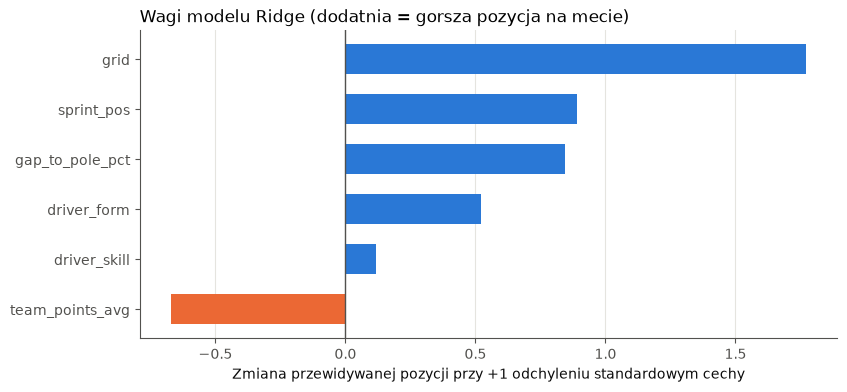

In [11]:
finishers = train_data[~train_data["retired"]]
final_ridge = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(finishers[PACE_FEATURES], finishers["finish"])
coefs = pd.Series(final_ridge[-1].coef_, index=PACE_FEATURES).sort_values()

fig, ax = plt.subplots()
ax.barh(coefs.index, coefs.values, color=[ORANGE if v < 0 else BLUE for v in coefs.values], height=0.6)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_xlabel("Zmiana przewidywanej pozycji przy +1 odchyleniu standardowym cechy")
ax.set_title("Wagi modelu Ridge (dodatnia = gorsza pozycja na mecie)", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

**Co tu się dzieje:**
- `final_ridge[-1]` — ostatni krok pipeline'u, czyli sam model `Ridge`; `.coef_` to jego wagi.
- Niebieski (dodatni) = cecha pogarsza przewidywaną pozycję (np. dalszy `grid`, większa strata do pole); pomarańczowy (ujemny) = poprawia (np. więcej punktów zespołu).

**Uwaga:** `grid`, `gap_to_pole_pct` i `sprint_pos` są silnie skorelowane (wszystkie mierzą tempo w tym weekendzie). Model może dowolnie „dzielić” wagę między nie, więc pojedynczych wartości nie należy nadinterpretować — patrz na znaki i rząd wielkości.

## 3.7 Najszybsze okrążenie: osobny klasyfikator

**Co robimy:** regresja logistyczna przewiduje **prawdopodobieństwo**, że kierowca zrobi najszybsze okrążenie. W każdym wyścigu typujemy kierowcę z najwyższym prawdopodobieństwem.

**Dlaczego osobno:** EDA pokazało, że najszybsze okrążenie często nie należy do zwycięzcy — to kwestia strategii (świeże opony pod koniec), a nie tylko tempa.

**Baseline:** pole sitter.

In [12]:
def evaluate_fl(predict_proba_fn):
    hits = []
    for r in TEST_ROUNDS:
        train = train_data[train_data["round"] < r]
        test = train_data[train_data["round"] == r]
        proba = predict_proba_fn(train, test)
        hits.append(test["fastest_lap"].values[np.argmax(proba)] == 1)
    return np.mean(hits)

def fl_baseline(train, test):
    return -test["grid"].values

def fl_logreg(train, test):
    model = make_pipeline(StandardScaler(), LogisticRegression(C=0.3))
    model.fit(train[FEATURES], train["fastest_lap"])
    return model.predict_proba(test[FEATURES])[:, 1]

print(f"Najszybsze okrążenie — trafienia: baseline (pole) {evaluate_fl(fl_baseline):.0%}, "
      f"regresja logistyczna {evaluate_fl(fl_logreg):.0%}  (losowe typowanie: {1/N_DRIVERS:.0%})")

Najszybsze okrążenie — trafienia: baseline (pole) 36%, regresja logistyczna 45%  (losowe typowanie: 5%)


**Co tu się dzieje:**
- `predict_proba(...)[:, 1]` — prawdopodobieństwo klasy 1 („zrobi najszybsze okrążenie”).
- `np.argmax(proba)` — indeks kierowcy z najwyższym prawdopodobieństwem w danym wyścigu.
- `C=0.3` — w `LogisticRegression` regularyzację ustawia się odwrotnie niż w `Ridge`: **mniejsze C = mocniejsza regularyzacja**. Przy 1 pozytywnym przykładzie na 22 wiersze to rozsądne.
- Baseline zwraca `-grid`, bo tu „większy = bardziej prawdopodobny”.

**Oczekiwania:** przy ~11 testowych wyścigach każdy wynik powyżej losowego (~5%) to już coś, ale nie oczekuj cudów. To najtrudniejszy z naszych celów.

## 3.8 Zapis tabeli cech

**Co robimy:** zapisujemy tabelę z cechami (łącznie z wierszami Singapuru) i listę cech.

**Dlaczego:** `04_prediction` wytrenuje model na wszystkich zakończonych wyścigach i przewidzi Singapur — bez powtarzania inżynierii cech.

In [13]:
data.to_csv("data/features.csv", index=False)
with open("data/feature_list.json", "w") as f:
    json.dump({"all": FEATURES, "pace": PACE_FEATURES}, f)
print("Wiersze Singapuru:", (~data["round"].isin(FINISHED_ROUNDS)).sum())

Wiersze Singapuru: 22


## Wnioski i pomysły na v2

Zapisz tu własne obserwacje po uruchomieniu. Kandydaci na kolejną iterację:
- **Tempo z treningu** (FP1, długie przejazdy z `stints` + `laps`) — dziś pominięte.
- **Kary na starcie** — `starting_grid` w API jest pusty; można je wyciągnąć z `race_control`.
- **Umiejętności względem partnera w 2026** (nie tylko historia).
- **Prawdopodobieństwa** zamiast samej kolejności — np. symulacja Monte Carlo z błędem modelu.
- **Specyfika toru** — tory uliczne vs szybkie (czy model powinien bardziej ufać `grid` w Singapurze?).